# Multilevel logistic model of the round-1 split measurements

**EXPLORATORY. POST-FREEZE. NOT PRE-REGISTERED.** Written 2026-09-28, after the study was frozen on
2026-08-12. It re-analyses data that already exists and changes none of the frozen findings. Nothing
here amends the pre-registration, re-opens band assignment, or touches the verdict arm, which never fired.

**Question.** The diagnostic established two things with descriptive statistics: models hold very
different baselines for reading `will X` as a present-tense assertion, and underneath those baselines
the models agree about *which* sentences read that way (item explains 61% of model-centred variance).
This notebook asks whether both findings survive a model that respects how the data were collected.

**Why a multilevel model.** The 960 `claim_true` judgements are not independent. They are
5 draws, nested in 192 *cells* (one sentence read by one model), nested in 48 *sentences*:

| level | unit | n |
|---|---|---|
| 1 | draw | 960 |
| 2 | sentence × model cell | 192 |
| 3 | sentence | 48 |

Treating the 960 draws as independent (ordinary logistic regression) overstates the evidence,
because five temperature-0 draws of the same prompt are close to one observation repeated.

**Model.** For draw *k* of sentence *i* by model *j*:

$$\operatorname{logit} P(\text{YES}_{ijk}) = \beta_0 + \beta_{j} + u_i + v_{ij},\qquad u_i\sim N(0,\sigma^2_{\text{sentence}}),\ v_{ij}\sim N(0,\sigma^2_{\text{cell}})$$

Model enters as a **fixed** effect: with four levels its variance cannot be estimated as a random
effect, and the four models are the population of interest, not a sample from one. Sonnet is the
reference level because it sits furthest from the others.

The R equivalent, for anyone who wants to check this in lme4:

```r
glmer(cbind(k, n - k) ~ model + (1 | item) + (1 | item:model),
      family = binomial, nAGQ = 1)   # nAGQ > 1 is not allowed with two random terms
```

lme4 would fit that by the Laplace approximation, so expect its variance estimates to differ
somewhat from the full quadrature used here, most of all with this many unanimous cells.

**Implementation.** lme4 is not available in this environment, so `glmm_core.py` fits the model by
maximum likelihood with 30-point Gauss–Hermite quadrature over both random effects (numpy + scipy).
The likelihood is integrated, not approximated, so nested models can be compared by likelihood ratio.
Before any result is read, the fitter is checked twice below: it must recover known parameters from
simulated data, and it must *fail to find* sentence variance when the sentence labels are shuffled.

`claim_false` is not modelled. It is the comprehension control, at 1.00 / 1.00 / 0.99 / 0.87, and
two models never say NO to it, which leaves nothing to estimate (complete separation).

In [1]:
import json, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2, spearmanr
sys.path.insert(0, ".")
import glmm_core as G

SEED = 20260806            # the seed pinned in the round-1 pre-registration
MODELS = ["sonnet-4.6", "nova-micro", "haiku-4.5", "opus-4.6"]   # sonnet = reference

raw = json.load(open("../results/round1-candidate-splits.json"))
d = pd.DataFrame(raw, columns=["item", "model", "member", "answer"])
assert len(d) == 1920 and d.item.nunique() == 48 and set(d.model) == set(MODELS)
d["yes"] = (d.answer == "YES").astype(int)

t = d[d.member == "true"]
cells = t.groupby(["item", "model"]).yes.agg(k="sum", n="size").reset_index()
assert len(cells) == 192 and (cells.n == 5).all()

X = np.column_stack([np.ones(len(cells))] + [(cells.model == m).astype(float) for m in MODELS[1:]])
item = pd.Categorical(cells.item).codes
print(f"{len(t)} claim_true draws -> {len(cells)} cells -> {cells.item.nunique()} sentences")
print("cells by YES count out of 5:", cells.k.value_counts().sort_index().to_dict())

960 claim_true draws -> 192 cells -> 48 sentences
cells by YES count out of 5: {0: 69, 1: 9, 2: 8, 3: 11, 4: 16, 5: 79}


Most cells are unanimous (0 or 5 of 5). That is what temperature 0 produces, and it is why the draw
level matters: an analysis that counts 960 independent judgements is really counting about 192.

## Check 1 — does the fitter recover known parameters?

In [2]:
truth = dict(beta=np.array([-1.2, 1.0, 2.0, 2.3]), s_item=1.5, s_cell=0.8)
rng = np.random.default_rng(SEED)
est = []
for rep in range(20):
    u = rng.normal(0, truth["s_item"], 48)
    v = rng.normal(0, truth["s_cell"], len(cells))
    k = rng.binomial(5, 1 / (1 + np.exp(-(X @ truth["beta"] + u[item] + v))))
    f = G.fit(k, np.full(len(cells), 5), X, item, levels=3)
    est.append(np.r_[f["beta"], f["sigma_item"], f["sigma_cell"]])
est = np.array(est)
rec = pd.DataFrame({"truth": np.r_[truth["beta"], truth["s_item"], truth["s_cell"]],
                    "mean estimate": est.mean(0), "sd across reps": est.std(0)},
                   index=["b0", "b_nova", "b_haiku", "b_opus", "sigma_sentence", "sigma_cell"]).round(2)
rec

,truth,mean estimate,sd across reps
b0,-1.2,-1.17,0.26
b_nova,1.0,0.95,0.32
b_haiku,2.0,2.02,0.33
b_opus,2.3,2.28,0.29
sigma_sentence,1.5,1.51,0.16
sigma_cell,0.8,0.83,0.19


Twenty simulated datasets with the real design (48 sentences × 4 models × 5 draws). Estimates land
near the truth; the variance components run slightly low, the usual small-sample shrinkage of
maximum-likelihood variance estimates.

## Check 2 — does it refuse to find sentence variance that isn't there?

In [3]:
# Shuffle which sentence each cell belongs to, within model. Model baselines survive; any real
# sentence-level agreement across models is destroyed. sigma_sentence should collapse.
rng = np.random.default_rng(SEED)
null_sig = []
for rep in range(20):
    shuffled = cells.copy()
    for m in MODELS:
        ix = shuffled.index[shuffled.model == m]
        shuffled.loc[ix, "k"] = rng.permutation(shuffled.loc[ix, "k"].values)
    f = G.fit(shuffled.k, shuffled.n, X, item, levels=3)
    null_sig.append(f["sigma_item"])
real = G.fit(cells.k, cells.n, X, item, levels=3)
print(f"sigma_sentence, shuffled labels: median {np.median(null_sig):.2f}, max {np.max(null_sig):.2f}")
print(f"sigma_sentence, real labels:     {real['sigma_item']:.2f}")
assert real["sigma_item"] > max(null_sig), "real sentence variance is not above the shuffled null"

sigma_sentence, shuffled labels: median 0.00, max 2.11
sigma_sentence, real labels:     5.10


## The nested models

In [4]:
m1 = G.fit(cells.k, cells.n, X, item, levels=1)               # ordinary logistic regression
m2 = G.fit(cells.k, cells.n, X, item, levels=2)               # + sentence
m3 = real                                                     # + sentence x model cell
m3_nomodel = G.fit(cells.k, cells.n, X[:, :1], item, levels=3)  # m3 without the model fixed effect
assert all(m["converged"] for m in (m1, m2, m3, m3_nomodel))

def lrt(big, small, df, boundary):
    lr = 2 * (big["loglik"] - small["loglik"])
    p = chi2.sf(lr, df) * (0.5 if boundary else 1.0)   # variance tested at 0: 50:50 chi-bar mixture
    return lr, df, p

rows = [("+ sentence random intercept", *lrt(m2, m1, 1, True)),
        ("+ sentence x model random intercept", *lrt(m3, m2, 1, True)),
        ("model fixed effect (in full model)", *lrt(m3, m3_nomodel, 3, False))]
pd.DataFrame(rows, columns=["term", "LR chi2", "df", "p"]).set_index("term").style.format(
    {"LR chi2": "{:.1f}", "p": "{:.1e}"})

,LR chi2,df,p
term,,,
+ sentence random intercept,435.1,1,6.5e-97
+ sentence x model random intercept,133.5,1,3.5e-31
model fixed effect (in full model),68.1,3,1.1e-14


Every level earns its place. The sentence term is the one that matters for the study: it tests
whether sentences differ in how present-tense they read *after* each model's own baseline is removed,
which is the claim the diagnostic made with model-centring and a correlation table.

In [5]:
names = ["intercept (sonnet)", "nova vs sonnet", "haiku vs sonnet", "opus vs sonnet"]
fx = pd.DataFrame({"logit": m3["beta"], "SE": m3["se"]}, index=names)
fx["z"] = fx.logit / fx.SE
fx["95% CI"] = [f"[{b-1.96*s:.2f}, {b+1.96*s:.2f}]" for b, s in zip(fx.logit, fx.SE)]

# opus vs haiku: contrast of two coefficients
cvec = np.array([0, 0, -1, 1, 0, 0])
est = cvec[:4] @ m3["beta"]; se = np.sqrt(cvec @ m3["cov"] @ cvec)
print(f"opus vs haiku: {est:.2f} logits (SE {se:.2f}, z {est/se:.2f})")

# marginal P(YES) per model, integrating over both random effects: must reproduce the raw rates
W = np.exp(G.LOGW[:, None] + G.LOGW[None, :])
def marginal(eta):
    g = eta + m3["sigma_item"] * G.NODES[:, None] + m3["sigma_cell"] * G.NODES[None, :]
    return float((W / (1 + np.exp(-g))).sum())
b = m3["beta"]
fx["model-implied P(YES)"] = [marginal(b[0] + (b[j] if j else 0)) for j in range(4)]
fx["observed P(YES)"] = [t[t.model == m].yes.mean() for m in MODELS]
fx.round(3)

opus vs haiku: 1.08 logits (SE 1.02, z 1.06)


,logit,SE,z,95% CI,model-implied P(YES),observed P(YES)
intercept (sonnet),-4.685,1.163,-4.027,"[-6.96, -2.40]",0.229,0.238
nova vs sonnet,4.324,1.077,4.015,"[2.21, 6.44]",0.477,0.500
haiku vs sonnet,7.571,1.341,5.648,"[4.94, 10.20]",0.676,0.683
opus vs sonnet,8.655,1.446,5.984,"[5.82, 11.49]",0.735,0.733


The fixed-effect logits are **conditional**: they compare models for the same sentence at the same
cell effect, which is why they are large. Read the right two columns instead. The model's implied
YES-rate for each reader, averaged over sentences, matches the observed rate, so the fit describes the
data it was given. Sonnet is separated from all three others; Opus and Haiku are not clearly separated
from each other.

## Where the variance lives

In [6]:
v_s, v_c, v_d = m3["sigma_item"]**2, m3["sigma_cell"]**2, G.LATENT_RESID
tot = v_s + v_c + v_d
p = X.shape[1]
ci = lambda ix: np.exp(m3["theta"][ix] + np.array([-1.96, 1.96]) * np.sqrt(m3["cov"][ix, ix]))
vc = pd.DataFrame({
    "sigma (logit)": [m3["sigma_item"], m3["sigma_cell"], np.sqrt(v_d)],
    "sigma 95% CI": [f"[{ci(p)[0]:.2f}, {ci(p)[1]:.2f}]", f"[{ci(p+1)[0]:.2f}, {ci(p+1)[1]:.2f}]", "fixed (pi^2/3)"],
    "share of residual variance": [v_s/tot, v_c/tot, v_d/tot]},
    index=["sentence", "sentence x model", "draw (latent logistic)"])
print(f"sentence share of model-adjusted variance, excluding draw noise: {v_s/(v_s+v_c):.0%}")
vc.style.format({"sigma (logit)": "{:.2f}", "share of residual variance": "{:.0%}"})

sentence share of model-adjusted variance, excluding draw noise: 71%


,sigma (logit),sigma 95% CI,share of residual variance
sentence,5.10,"[3.47, 7.49]",65%
sentence x model,3.26,"[2.40, 4.43]",27%
draw (latent logistic),1.81,fixed (pi^2/3),8%


**Reading this.** Once model baselines are removed, the sentence is the largest source of variation
by a wide margin: about 64% of the residual latent variance, or 71% of the variance that is not draw
noise. The sentence × model term is the part of each reading that is idiosyncratic to one
model. Draw noise is small, as temperature 0 should make it.

This is the diagnostic's 61% finding restated as a model. The two numbers are not the same statistic:
61% was a sum-of-squares share on the probability scale; this is a variance-component share on the
latent logit scale, where the level-1 residual is fixed at π²/3 by convention. They agree in direction
and rough size, which is the point.

The large σ values come from the many unanimous cells: when most cells are 0/5 or 5/5, the latent
scale stretches to fit them. The shares are more stable than the σ values themselves.

## Figure — each sentence's shared pull toward a present-tense reading

Spearman rho, sentence effect vs each model's own rates: {'sonnet-4.6': np.float64(0.72), 'nova-micro': np.float64(0.78), 'haiku-4.5': np.float64(0.83), 'opus-4.6': np.float64(0.79)}


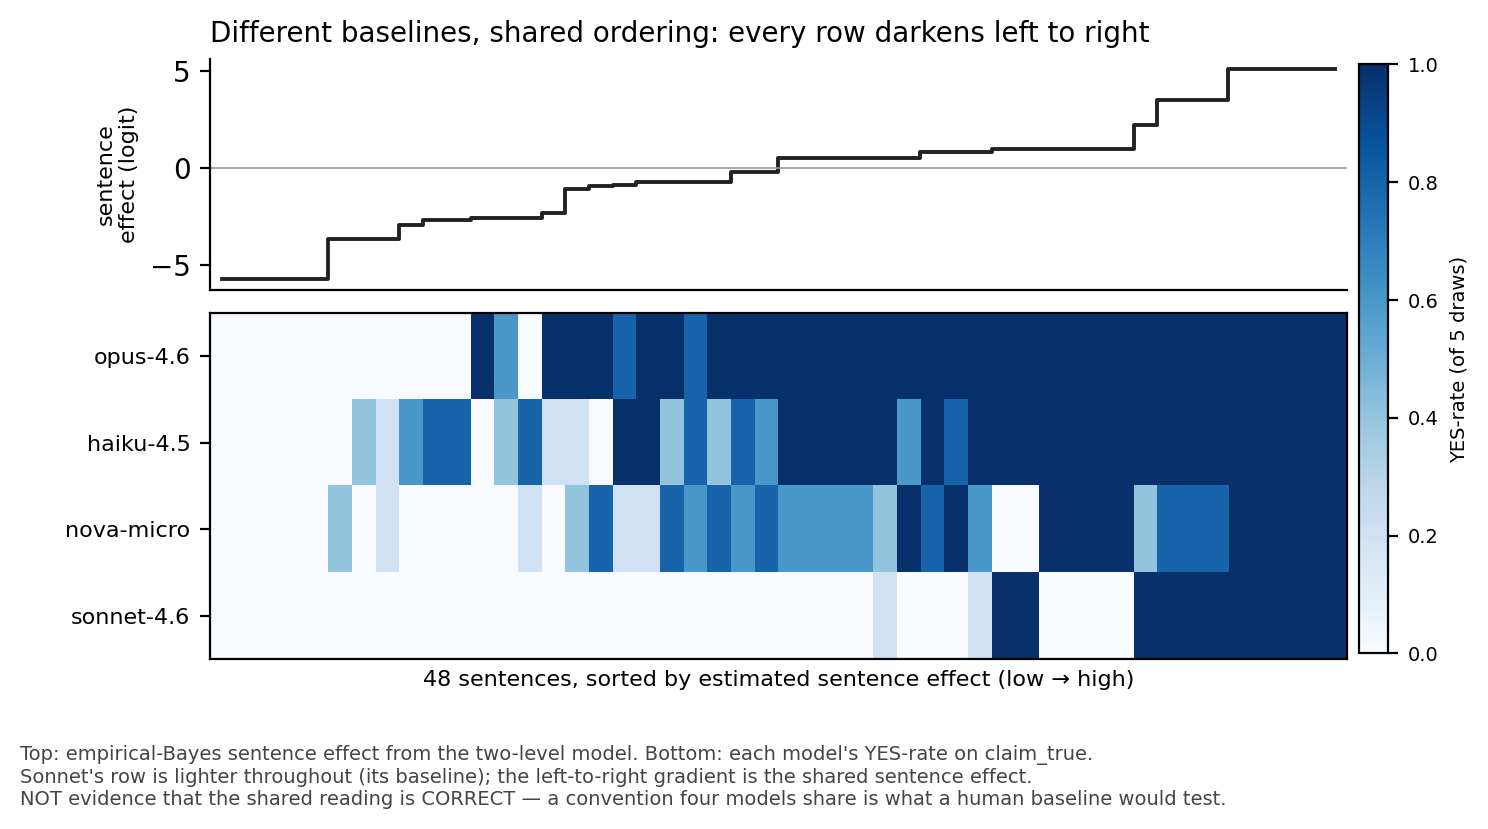

In [7]:
# empirical-Bayes estimates of u_i from the two-level model (sentence effect with model fixed)
u_hat = G.blup_item(cells.k, cells.n, X, item, m2)
labels = pd.Categorical(cells.item).categories
order = np.argsort(u_hat)
per_model = cells.assign(rate=cells.k / cells.n).pivot(index="item", columns="model", values="rate").loc[labels]

rows = MODELS[::-1]   # opus on top, sonnet at the bottom
grid = per_model[rows].values[order].T

fig, (ax0, ax) = plt.subplots(2, 1, figsize=(7.6, 3.9), dpi=200, sharex=True,
                              gridspec_kw={"height_ratios": [1, 1.5], "hspace": .08})
ax0.plot(np.arange(len(labels)), u_hat[order], color="#222", lw=1.4, drawstyle="steps-mid")
ax0.axhline(0, color="#999", lw=.6)
ax0.set_ylabel("sentence\neffect (logit)", fontsize=8)
ax0.spines[["top", "right"]].set_visible(False)
im = ax.imshow(grid, aspect="auto", cmap="Blues", vmin=0, vmax=1, interpolation="nearest")
ax.set_yticks(range(len(rows))); ax.set_yticklabels(rows, fontsize=8)
ax.set_xticks([]); ax.set_xlabel("48 sentences, sorted by estimated sentence effect (low → high)", fontsize=8)
cb = fig.colorbar(im, ax=[ax0, ax], fraction=.025, pad=.01); cb.set_label("YES-rate (of 5 draws)", fontsize=7)
cb.ax.tick_params(labelsize=7)
ax0.set_title("Different baselines, shared ordering: every row darkens left to right",
              fontsize=10, loc="left")
fig.text(0.0, 0.0, "Top: empirical-Bayes sentence effect from the two-level model. Bottom: each model's "
         "YES-rate on claim_true.\nSonnet's row is lighter throughout (its baseline); the left-to-right "
         "gradient is the shared sentence effect.\nNOT evidence that the shared reading is CORRECT — a "
         "convention four models share is what a human baseline would test.",
         fontsize=7, va="top", color="#444")
fig.savefig("figures/mixed-model-sentence-effects.png", bbox_inches="tight")
rho = [spearmanr(u_hat, per_model[m].values).statistic for m in MODELS]
print("Spearman rho, sentence effect vs each model's own rates:", dict(zip(MODELS, np.round(rho, 2))))
plt.show()

## What this adds, and what it does not

**Adds.** The two diagnostic findings hold under a model that accounts for nesting: the model offsets
are significant (LR χ² on 3 df), and there is substantial sentence-level variance shared across all
four readers after those offsets are removed. Model-centring was the right intuition; the multilevel
model is the principled version of it, and it does not require choosing new thresholds.

**Does not add.**
- It does not rescue the pre-registered factor or license adopting correction 3. That remains a
  decision about the pre-registration, not about the statistics.
- It does not say the shared reading is *correct*. All readers are language models; the human
  baseline is still missing.
- It is exploratory. It was specified after the data were seen, by someone who had read the diagnostic.